In [ ]:
import inspect
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from scipy.special import expit, softmax
from sklearn.datasets import load_breast_cancer, load_iris, make_moons, make_classification
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    log_loss, confusion_matrix, mean_squared_error, mean_absolute_error,
    classification_report)
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
random_state = 42

In [ ]:
def make_logistic_model(C=1.0, solver='lbfgs', regularization='l2', max_iter=3000, tol=1e-5, class_weight=None):
    parameters = {'C': C, 'solver': solver, 'max_iter': max_iter, 'tol': tol, 'class_weight': class_weight, 'random_state': random_state}
    parameters['penalty'] = regularization
    return LogisticRegression(**parameters)

### Подготовка данных - breast cancer

In [ ]:
cancer = load_breast_cancer(as_frame=True)
cancer_features = cancer.data.copy()
cancer_target = (1 - cancer.target).rename('malignant')
cancer_train_validation_indices = train_test_split(
    cancer_features.index,
    test_size=0.2,
    stratify=cancer_target,
    random_state=random_state,
)
cancer_development_indices = cancer_train_validation_indices[0]
cancer_test_indices = cancer_train_validation_indices[1]
cancer_train_validation_split = train_test_split(
    cancer_development_indices,
    test_size=0.25,
    stratify=cancer_target.loc[cancer_development_indices],
    random_state=random_state,
)
cancer_train_indices = cancer_train_validation_split[0]
cancer_validation_indices = cancer_train_validation_split[1]
cancer_train_features = cancer_features.loc[cancer_train_indices]
cancer_validation_features = cancer_features.loc[cancer_validation_indices]
cancer_test_features = cancer_features.loc[cancer_test_indices]
cancer_train_target = cancer_target.loc[cancer_train_indices]
cancer_validation_target = cancer_target.loc[cancer_validation_indices]
cancer_test_target = cancer_target.loc[cancer_test_indices]

split_summary = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'rows': [len(cancer_train_indices), len(cancer_validation_indices), len(cancer_test_indices)]
})
split_summary

,split,rows
0,train,341
1,validation,114
2,test,114


In [ ]:
cancer_scaler = StandardScaler()
cancer_train_scaled = pd.DataFrame(cancer_scaler.fit_transform(cancer_train_features), columns=cancer_features.columns, index=cancer_train_indices)
cancer_validation_scaled = pd.DataFrame(cancer_scaler.transform(cancer_validation_features), columns=cancer_features.columns, index=cancer_validation_indices)
cancer_train_scaled.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
194,0.193816,0.868298,0.331466,0.032564,0.613748,1.783766,1.045534,1.032611,-0.251128,0.620637,...,-0.052887,0.315841,0.318314,-0.179176,-0.009969,1.342242,0.885112,0.893857,0.151890,0.201773
46,-1.660366,-0.594469,-1.630154,-1.273254,-0.677435,-0.820919,-0.904895,-1.075643,-0.134430,0.371642,...,-1.497605,-0.650646,-1.471377,-1.105073,-0.090384,-0.756877,-0.968367,-1.338773,0.316997,-0.554997
332,-0.818973,0.099025,-0.815129,-0.757602,0.683921,-0.663777,-1.042776,-1.033256,0.489177,-0.328197,...,-0.885285,-0.016285,-0.898057,-0.774139,0.447129,-1.005697,-1.231826,-1.421058,0.611043,-1.074545
76,-0.176242,-1.949308,-0.171731,-0.279497,2.347021,0.030016,-0.234252,0.441833,2.177655,0.574963,...,-0.458935,-2.223263,-0.476456,-0.485021,0.561404,-0.742845,-0.889543,-0.603520,-0.304117,-0.682688
124,-0.220760,-0.697804,-0.244652,-0.295351,-1.719504,-0.561146,-0.080191,-0.513793,-1.399877,-0.630233,...,-0.422391,-0.519456,-0.458075,-0.439622,-1.241595,-0.008057,0.276472,-0.365015,-1.345073,-0.426721


### Утилиты для оценки качества

In [ ]:
def classification_metrics(model, features, target):
    predictions = model.predict(features)
    positive_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(features)[:, positive_column]
    return {
        'accuracy': accuracy_score(target, predictions),
        'macro_f1': f1_score(target, predictions, average='macro', zero_division=0),
        'precision_1': precision_score(target, predictions, zero_division=0),
        'recall_1': recall_score(target, predictions, zero_division=0),
        'roc_auc': roc_auc_score(target, probabilities),
        'log_loss': log_loss(target, probabilities, labels=[0, 1])
    }

def regression_metrics(model, features, target):
    predictions = model.predict(features)
    return {'rmse': np.sqrt(mean_squared_error(target, predictions)), 'mae': mean_absolute_error(target, predictions)}

def draw_binary_surface(model, train_features, train_target, validation_features, validation_target, ax, title, probability=True):
    all_features = np.vstack([train_features, validation_features])
    lower_limits = all_features.min(axis=0) - 0.4
    upper_limits = all_features.max(axis=0) + 0.4
    horizontal_values = np.linspace(lower_limits[0], upper_limits[0], 160)
    vertical_values = np.linspace(lower_limits[1], upper_limits[1], 160)
    mesh_coordinates = np.meshgrid(horizontal_values, vertical_values)
    horizontal_grid = mesh_coordinates[0]
    vertical_grid = mesh_coordinates[1]
    query_features = np.column_stack([horizontal_grid.ravel(), vertical_grid.ravel()])

    if probability:
        positive_column = list(model.classes_).index(1)
        surface = model.predict_proba(query_features)[:, positive_column].reshape(horizontal_grid.shape)
        image = ax.contourf(horizontal_grid, vertical_grid, surface, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.55, vmin=0, vmax=1)
        if surface.min() < 0.5 < surface.max():
            ax.contour(horizontal_grid, vertical_grid, surface, levels=[0.5], colors='black', linewidths=1)
    else:
        surface = model.predict(query_features).reshape(horizontal_grid.shape)
        image = ax.contourf(horizontal_grid, vertical_grid, surface, levels=[-0.5, 0.5, 1.5], cmap='RdBu_r', alpha=0.35)

    ax.scatter(train_features[:, 0], train_features[:, 1], c=train_target, cmap='RdBu_r', vmin=0, vmax=1, s=22, edgecolor='white', linewidth=0.4, label='train')
    ax.scatter(
        validation_features[:, 0],
        validation_features[:, 1],
        c=validation_target,
        cmap='RdBu_r',
        vmin=0, vmax=1, s=40,
        marker='^',
        edgecolor='black',
        linewidth=0.6,
        label='validation',
    )
    ax.set(xlabel='Признак 1', ylabel='Признак 2', title=title, xlim=(lower_limits[0], upper_limits[0]), ylim=(lower_limits[1], upper_limits[1]))
    ax.legend(loc='best')
    return image

### Константный бейзлайн

In [ ]:
cancer_dummy = DummyClassifier(strategy='prior')
cancer_dummy.fit(cancer_train_features, cancer_train_target)
result = classification_metrics(cancer_dummy, cancer_validation_features, cancer_validation_target)
cancer_dummy_validation = pd.Series(result, name='dummy_validation')
cancer_dummy_validation

,dummy_validation
accuracy,0.622807
macro_f1,0.383784
precision_1,0.000000
recall_1,0.000000
roc_auc,0.500000
log_loss,0.662722


### Логистическая регрессия

Сначала знакомая линейная комбинация $z=b+w^\top x$. Затем $p=\sigma(z)=1/(1+\exp(-z))$.
Итоговый класс 1, если вероятность превышает выбранный порог, иначе 0.

Логистическая регрессия - классификатор, несмотря на слово «регрессия». Она моделирует логарифм шансов: $log(p/(1-p))=z$. Шансы - не вероятность: при p=0.8 шансы равны 4, а не 0.8.

#### Роль коэффициентов

In [ ]:
probability_examples = np.array([0.01, 0.1, 0.5, 0.8, 0.9, 0.99])
logit_examples = np.log(probability_examples / (1 - probability_examples))
probability_table = pd.DataFrame({
    'probability': probability_examples,
    'odds': probability_examples / (1 - probability_examples),
    'logit': logit_examples,
    'sigmoid_logit': expit(logit_examples)
})
probability_table

,probability,odds,logit,sigmoid_logit
0,0.01,0.010101,-4.595120,0.01
1,0.10,0.111111,-2.197225,0.10
2,0.50,1.000000,0.000000,0.50
3,0.80,4.000000,1.386294,0.80
4,0.90,9.000000,2.197225,0.90
5,0.99,99.000000,4.595120,0.99


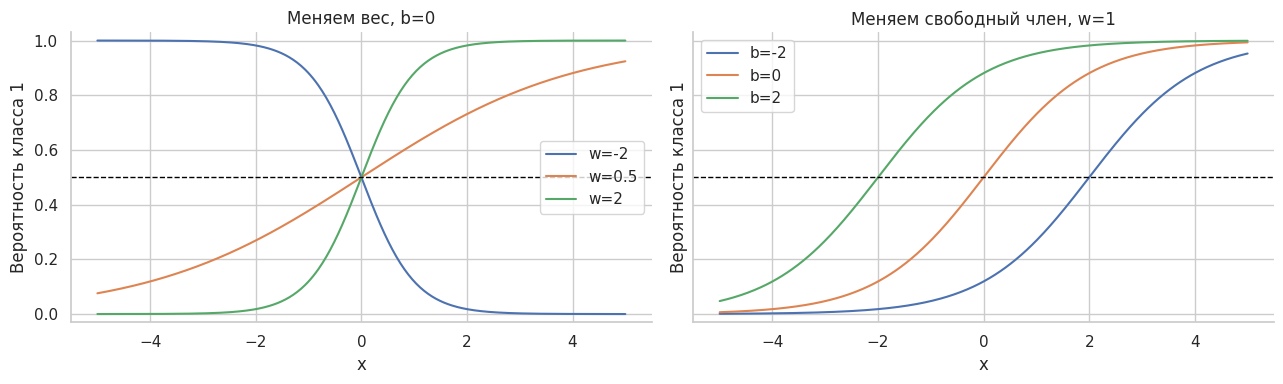

In [ ]:
feature_values = np.linspace(-5, 5, 400)
figure_axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for weight in [-2, 0.5, 2]:
    axes[0].plot(feature_values, expit(weight * feature_values), label=f'w={weight}')
for intercept in [-2, 0, 2]:
    axes[1].plot(feature_values, expit(feature_values + intercept), label=f'b={intercept}')
for ax in axes:
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='x', ylabel='Вероятность класса 1', ylim=(-0.03, 1.03))
    ax.legend()

axes[0].set_title('Меняем вес, b=0')
axes[1].set_title('Меняем свободный член, w=1')
plt.tight_layout()
plt.show()

Свободный член b меняет значение x, при котором z=0; знак w задаёт направление изменения p, а модуль w — резкость перехода. Изменение вероятности нелинейно: одинаковое приращение z гораздо заметнее около p=0.5, чем в насыщении около 0 или 1.

#### Почему не просто линейная регрессия на метках 0/1?

Обучить её можно, но она минимизирует квадрат ошибки и не ограничивает выход интервалом [0, 1]. Обрезка результата не превращает MSE в вероятностное обучение.

На специально сконструированных метках сравним продолжение линейной функции и сигмоиды:

In [ ]:
range_features = np.linspace(-3, 3, 60).reshape(-1, 1)
range_target = (range_features[:, 0] > 0).astype(int)
range_linear = LinearRegression()
range_logistic = make_logistic_model(C=1.0)
range_linear.fit(range_features, range_target)
range_logistic.fit(range_features, range_target)
range_grid = np.linspace(-7, 7, 400).reshape(-1, 1)
range_predictions = pd.DataFrame({'x': range_grid[:, 0], 'linear': range_linear.predict(range_grid), 'logistic': range_logistic.predict_proba(range_grid)[:, 1]})

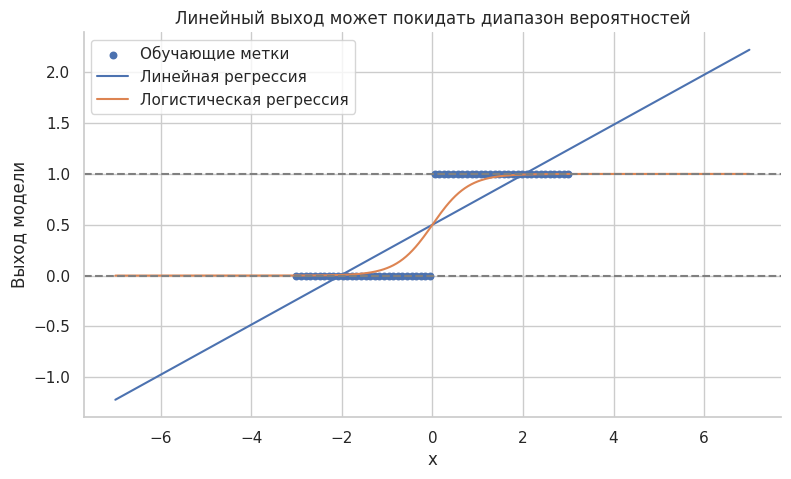

In [ ]:
figure = plt.figure(figsize=(9, 5))
plt.scatter(range_features[:, 0], range_target, label='Обучающие метки', s=22)
plt.plot(range_predictions['x'], range_predictions['linear'], label='Линейная регрессия')
plt.plot(range_predictions['x'], range_predictions['logistic'], label='Логистическая регрессия')
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel('x')
plt.ylabel('Выход модели')
plt.title('Линейный выход может покидать диапазон вероятностей')
plt.legend()
plt.show()

Мы можем рассматривать задачу бинарной классификации как задачу предсказания вероятности события класса 1.

Для решения этой задачи можно научить линейную модель правильно предсказывать какой-то объект, связанный с вероятностью, но с диапазоном значений ***R***, и преобразовать ответы модели в вероятность.

#### Какой объект связан с вероятностью по смыслу и имеет область значений ***R***?



**Шанс** - отношение вероятности, что событие произойдет, к вероятности, что оно не произойдет - $odds = \frac{P_i}{1-P_i}$

Прологаририфмировав шансы можно перейти в область значений ***R*** к логитам.

$logit = log(\frac{P_i}{1-P_i})$

Также результат такого преобразования симметричен относительно точки 0.5

И небольшие изменения вероятностей приводят к большим изменениям логитов, когда вероятности находятся вблизи 0 и 1

=> давайте предсказывать логиты!

$logit = log(\frac{P_i}{1-P_i}) = b_0 + b_1x_1 + ... + b_nx_n$


В итоге получается, что несмотря на класс "линейные модели" логистическая регрессия линейно оценивает логарифмы шансов, а связь с самими вероятностями нелинейна

#### Как перейти от логитов к вероятностям?




* Используем преобразование, обратное логарифму для получения шансов:


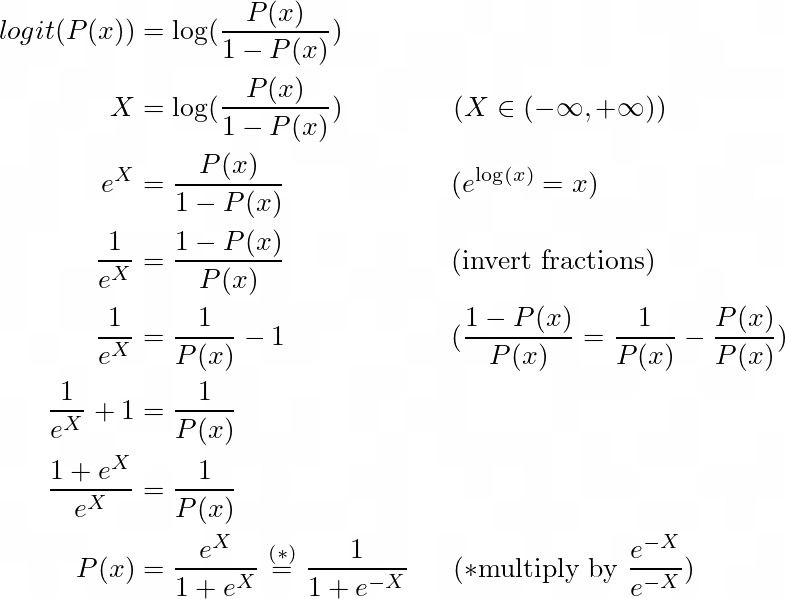

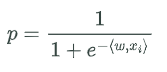

#### А какая функция потерь?



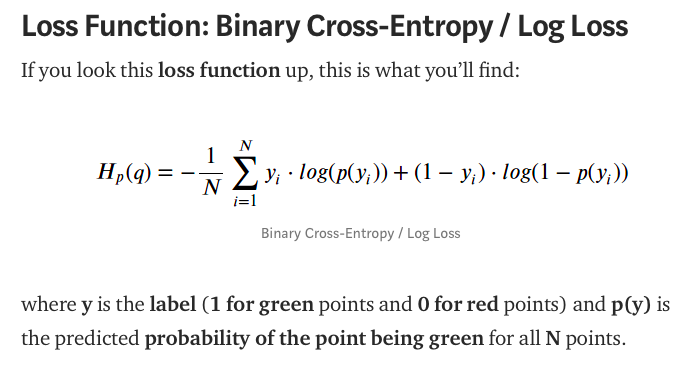

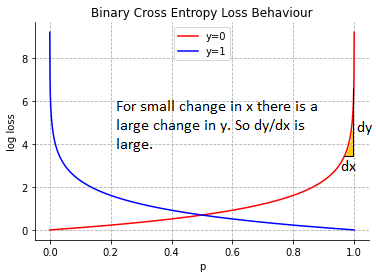

Предположим, мы работаем синоптиками.

При составлении прогноза погоды, мы предсказали на завтра "вероятность дождя" = $p$.

После наступления завтра нас штрафуют на $-log(p$) тысяч рублей, если дождь пошёл (и $−log(1−p)$, если нет).

- Сказать "99% будет дождь" и ошибиться - огромный штраф ($−log(0.01) ≈ 2$), а "51% будет дождь" и ошибиться - сравнительно небольшой ($−log(0.49) ≈ 0.31$).
- Правильно и уверенно предсказывать почти бесплатно: $−log(0.99) ≈ 0.004$.

Поэтому log‑loss воспитывает осторожную, калиброванную модель.

#### Обучим модель из sklearn

In [ ]:
logreg = LogisticRegression()
logreg.fit(cancer_train_scaled, cancer_train_target)
y_preds_logreg = logreg.predict(cancer_validation_scaled)
print(classification_report(cancer_validation_target, y_preds_logreg))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98        71
           1       0.95      0.98      0.97        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



#### Пройдемся по гиперпараметрам модели

##### solver

Сравним L2-модели на одних и тех же стандартизированных train и validation. Сохраняем предупреждения, число итераций, время и метрики.

In [ ]:
solver_rows = []
solver_models = {}

for solver in ['lbfgs', 'newton-cg', 'newton-cholesky', 'liblinear', 'sag', 'saga']:
    solver_model = make_logistic_model(solver=solver, max_iter=6000, tol=1e-5)
    started_at = time.perf_counter()
    with warnings.catch_warnings(record=True) as captured_warnings:
        warnings.simplefilter('always')
        solver_model.fit(cancer_train_scaled, cancer_train_target)
    elapsed_seconds = time.perf_counter() - started_at
    solver_result = classification_metrics(solver_model, cancer_validation_scaled, cancer_validation_target)
    solver_result['solver'] = solver
    solver_result['iterations'] = int(solver_model.n_iter_.max())
    solver_result['seconds'] = elapsed_seconds
    solver_result['warnings'] = ' | '.join(str(item.message) for item in captured_warnings)
    solver_rows.append(solver_result)
    solver_models[solver] = solver_model

solver_results = pd.DataFrame(solver_rows).set_index('solver')
solver_results

,accuracy,macro_f1,precision_1,recall_1,roc_auc,log_loss,iterations,seconds,warnings
solver,,,,,,,,,
lbfgs,0.973684,0.97212,0.954545,0.976744,0.995742,0.071975,24,0.011046,scipy.optimize: The `disp` and `iprint` option...
newton-cg,0.973684,0.97212,0.954545,0.976744,0.995742,0.071962,9,0.010335,
newton-cholesky,0.973684,0.97212,0.954545,0.976744,0.995742,0.071957,8,0.012731,
liblinear,0.973684,0.97212,0.954545,0.976744,0.995742,0.072229,9,0.019373,
sag,0.973684,0.97212,0.954545,0.976744,0.995742,0.071959,557,0.448074,
saga,0.973684,0.97212,0.954545,0.976744,0.995742,0.071964,985,0.641894,


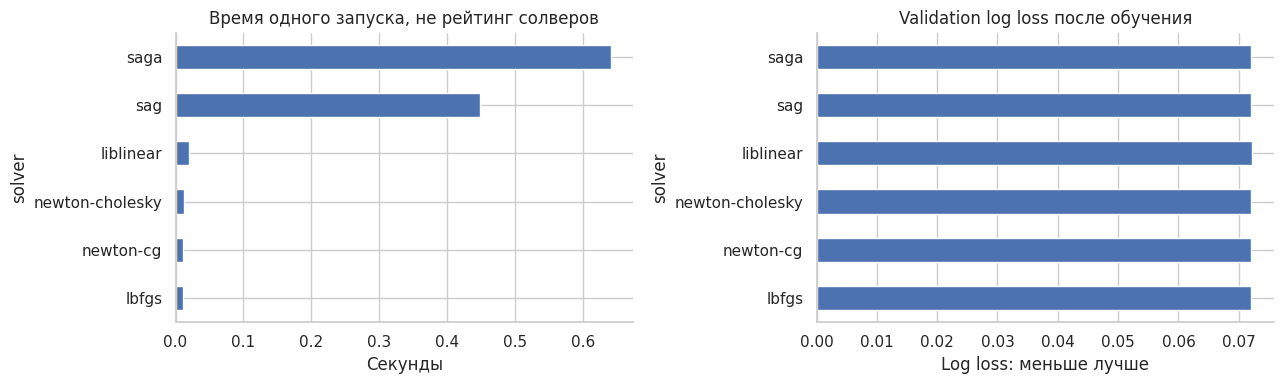

In [ ]:
figure_axes = plt.subplots(1, 2, figsize=(13, 4))
figure = figure_axes[0]
axes = figure_axes[1]
solver_results['seconds'].plot.barh(ax=axes[0], title='Время одного запуска, не рейтинг солверов')
solver_results['log_loss'].plot.barh(ax=axes[1], title='Validation log loss после обучения')
axes[0].set_xlabel('Секунды')
axes[1].set_xlabel('Log loss: меньше лучше')
plt.tight_layout()
plt.show()

##### C и ограничение сложности

В sklearn меньший C означает более сильную регуляризацию. Веса сжимаются, но связь "меньше норма - обязательно выше качество" неверна. Чрезмерный штраф может привести к недообучению.

Сравним набор заранее выбранных C, используя validation log loss

In [ ]:
regularization_rows = []
regularization_models = {}

for regularization_strength in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]:
    regularization_model = make_logistic_model(C=regularization_strength, max_iter=6000)
    regularization_model.fit(cancer_train_scaled, cancer_train_target)
    regularization_rows.append({
        'C': regularization_strength,
        'weight_norm': np.linalg.norm(regularization_model.coef_),
        'train_log_loss': log_loss(cancer_train_target, regularization_model.predict_proba(cancer_train_scaled)),
        'validation_log_loss': log_loss(cancer_validation_target, regularization_model.predict_proba(cancer_validation_scaled))
    })
    regularization_models[regularization_strength] = regularization_model

regularization_results = pd.DataFrame(regularization_rows)
best_logistic_position = regularization_results['validation_log_loss'].idxmin()
best_logistic_C = regularization_results.loc[best_logistic_position, 'C']
selected_logistic = regularization_models[best_logistic_C]
regularization_results

,C,weight_norm,train_log_loss,validation_log_loss
0,0.001,0.250909,0.395307,0.400587
1,0.010,0.744185,0.191069,0.196775
2,0.100,1.659068,0.093540,0.103564
3,1.000,3.499225,0.053153,0.071975
4,10.000,8.998051,0.026521,0.081924
5,100.000,22.353291,0.008678,0.135935


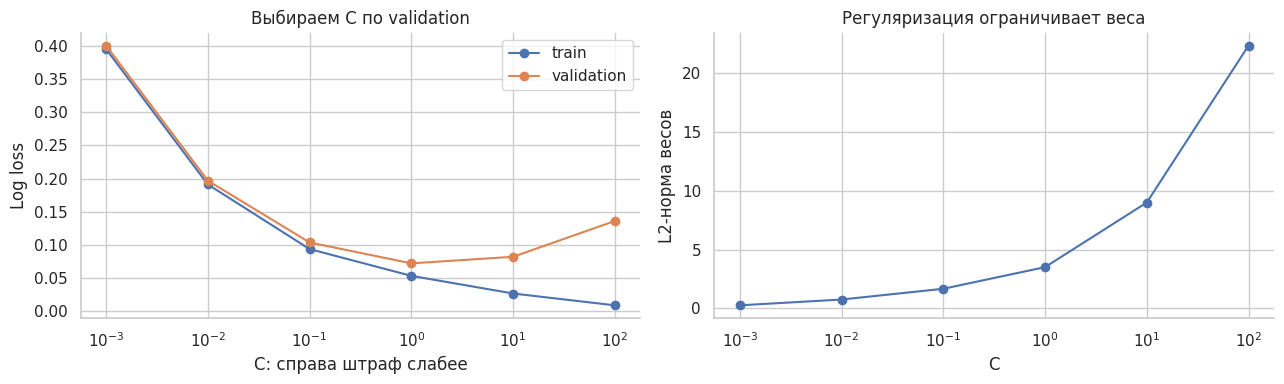

In [ ]:
figure_axes = plt.subplots(1, 2, figsize=(13, 4))
figure = figure_axes[0]
axes = figure_axes[1]
axes[0].semilogx(regularization_results['C'], regularization_results['train_log_loss'], marker='o', label='train')
axes[0].semilogx(regularization_results['C'], regularization_results['validation_log_loss'], marker='o', label='validation')
axes[0].set(xlabel='C: справа штраф слабее', ylabel='Log loss', title='Выбираем C по validation')
axes[0].legend()
axes[1].semilogx(regularization_results['C'], regularization_results['weight_norm'], marker='o')
axes[1].set(xlabel='C', ylabel='L2-норма весов', title='Регуляризация ограничивает веса')
plt.tight_layout()
plt.show()

#### Линейная граница, нелинейная вероятность

Используем make_moons: два признака с нелинейным разделением.


In [ ]:
moons_data = make_moons(n_samples=420, noise=0.25, random_state=random_state)
moons_features = moons_data[0]
moons_target = moons_data[1]
moons_split = train_test_split(np.arange(len(moons_target)), test_size=0.3, stratify=moons_target, random_state=random_state)
moons_train_indices = moons_split[0]
moons_validation_indices = moons_split[1]
moons_train_features = moons_features[moons_train_indices]
moons_validation_features = moons_features[moons_validation_indices]
moons_train_target = moons_target[moons_train_indices]
moons_validation_target = moons_target[moons_validation_indices]
moons_logistic_models = {}

for regularization_strength in [0.01, 1.0, 100.0]:
    moons_logistic = make_logistic_model(C=regularization_strength)
    moons_logistic.fit(moons_train_features, moons_train_target)
    moons_logistic_models[regularization_strength] = moons_logistic

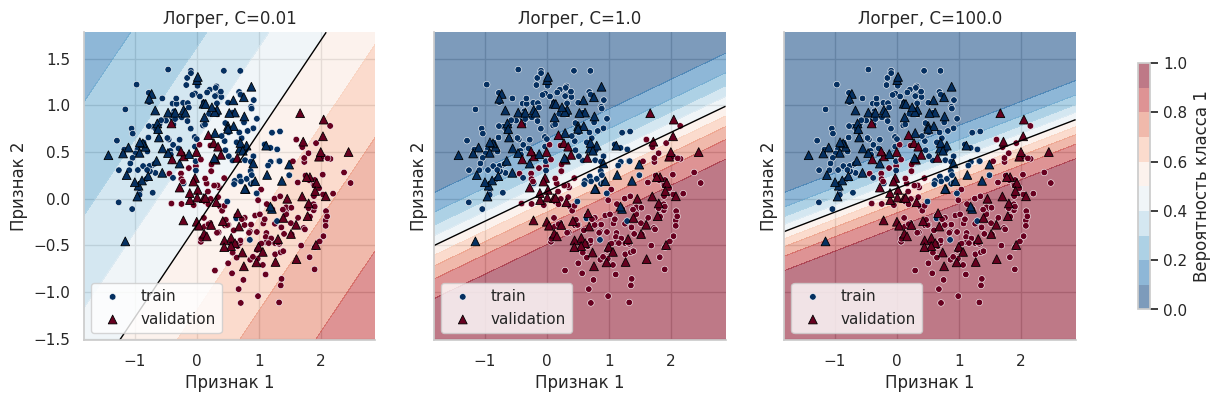

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for ax, model_item in zip(axes, moons_logistic_models.items()):
    regularization_strength = model_item[0]
    moons_logistic = model_item[1]
    image = draw_binary_surface(
        moons_logistic,
        moons_train_features,
        moons_train_target,
        moons_validation_features,
        moons_validation_target,
        ax,
        f'Логрег, C={regularization_strength}'
    )

figure.colorbar(image, ax=axes.tolist(), label='Вероятность класса 1', shrink=0.8)
plt.show()

####  Многоклассовая модель: несколько оценок и softmax

На датасете ирисов сохраним все четыре признака. Для каждого класса модель вычисляет линейную оценку z_k. Softmax превращает оценки в вероятности: $exp(z_k) / sum_j exp(z_j)$.

В современных версиях multinomial используется автоматически для подходящих солверов. Альтернатива OvR обучает несколько бинарных моделей «класс против остальных»

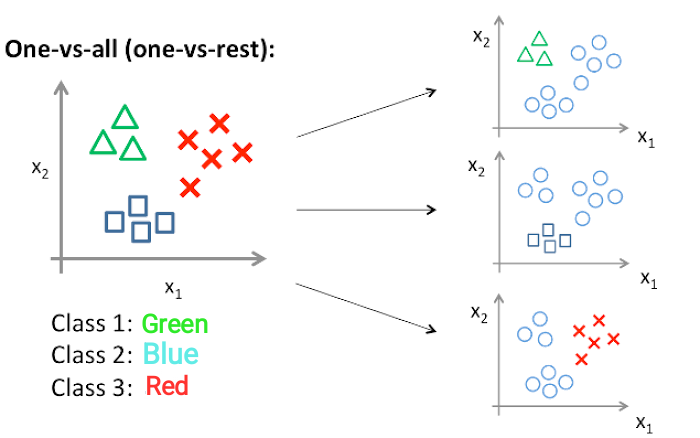

In [ ]:
iris = load_iris(as_frame=True)
iris_split = train_test_split(np.arange(len(iris.target)), test_size=0.3, stratify=iris.target, random_state=random_state)
iris_train_indices = iris_split[0]
iris_validation_indices = iris_split[1]
iris_scaler = StandardScaler()
iris_train_scaled = iris_scaler.fit_transform(iris.data.iloc[iris_train_indices])
iris_validation_scaled = iris_scaler.transform(iris.data.iloc[iris_validation_indices])
iris_train_target = iris.target.iloc[iris_train_indices]
iris_validation_target = iris.target.iloc[iris_validation_indices]

multiclass_logistic = make_logistic_model()
multiclass_logistic.fit(iris_train_scaled, iris_train_target)
multiclass_logits = multiclass_logistic.decision_function(iris_validation_scaled[:5])
manual_multiclass_probabilities = softmax(multiclass_logits, axis=1)

ovr_logistic = OneVsRestClassifier(make_logistic_model(solver='liblinear'))
ovr_logistic.fit(iris_train_scaled, iris_train_target)
multiclass_results = pd.DataFrame({
    'model': ['multinomial', 'OvR'],
    'validation_macro_f1': [f1_score(iris_validation_target, multiclass_logistic.predict(iris_validation_scaled), average='macro'),
                            f1_score(iris_validation_target, ovr_logistic.predict(iris_validation_scaled), average='macro')]})
multiclass_results

,model,validation_macro_f1
0,multinomial,0.910714
1,OvR,0.797980


### k ближайших соседей  - kNN

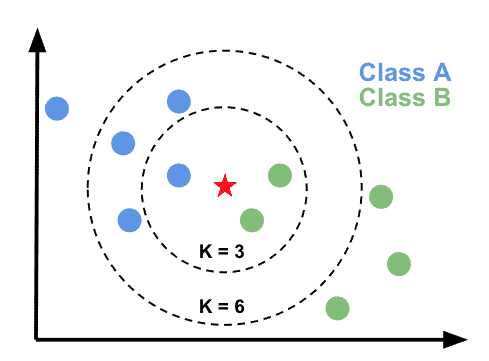

kNN хранит обучающие объекты и ищет ближайшие к запросу. Для классификации используем голоса или доли классов, для регрессии среднее ответов.

In [ ]:
knn_raw = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn_scaled = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn_raw.fit(cancer_train_features, cancer_train_target)
knn_scaled.fit(cancer_train_scaled, cancer_train_target)
knn_scale_results = pd.DataFrame([
    classification_metrics(knn_raw, cancer_validation_features, cancer_validation_target),
    classification_metrics(knn_scaled, cancer_validation_scaled, cancer_validation_target)], index=['Без масштабирования', 'StandardScaler'])
knn_scale_results

,accuracy,macro_f1,precision_1,recall_1,roc_auc,log_loss
Без масштабирования,0.938596,0.934348,0.928571,0.906977,0.976908,0.433410
StandardScaler,0.973684,0.971583,1.000000,0.930233,0.996725,0.069206


#### Ускоряем поиск - ball tree

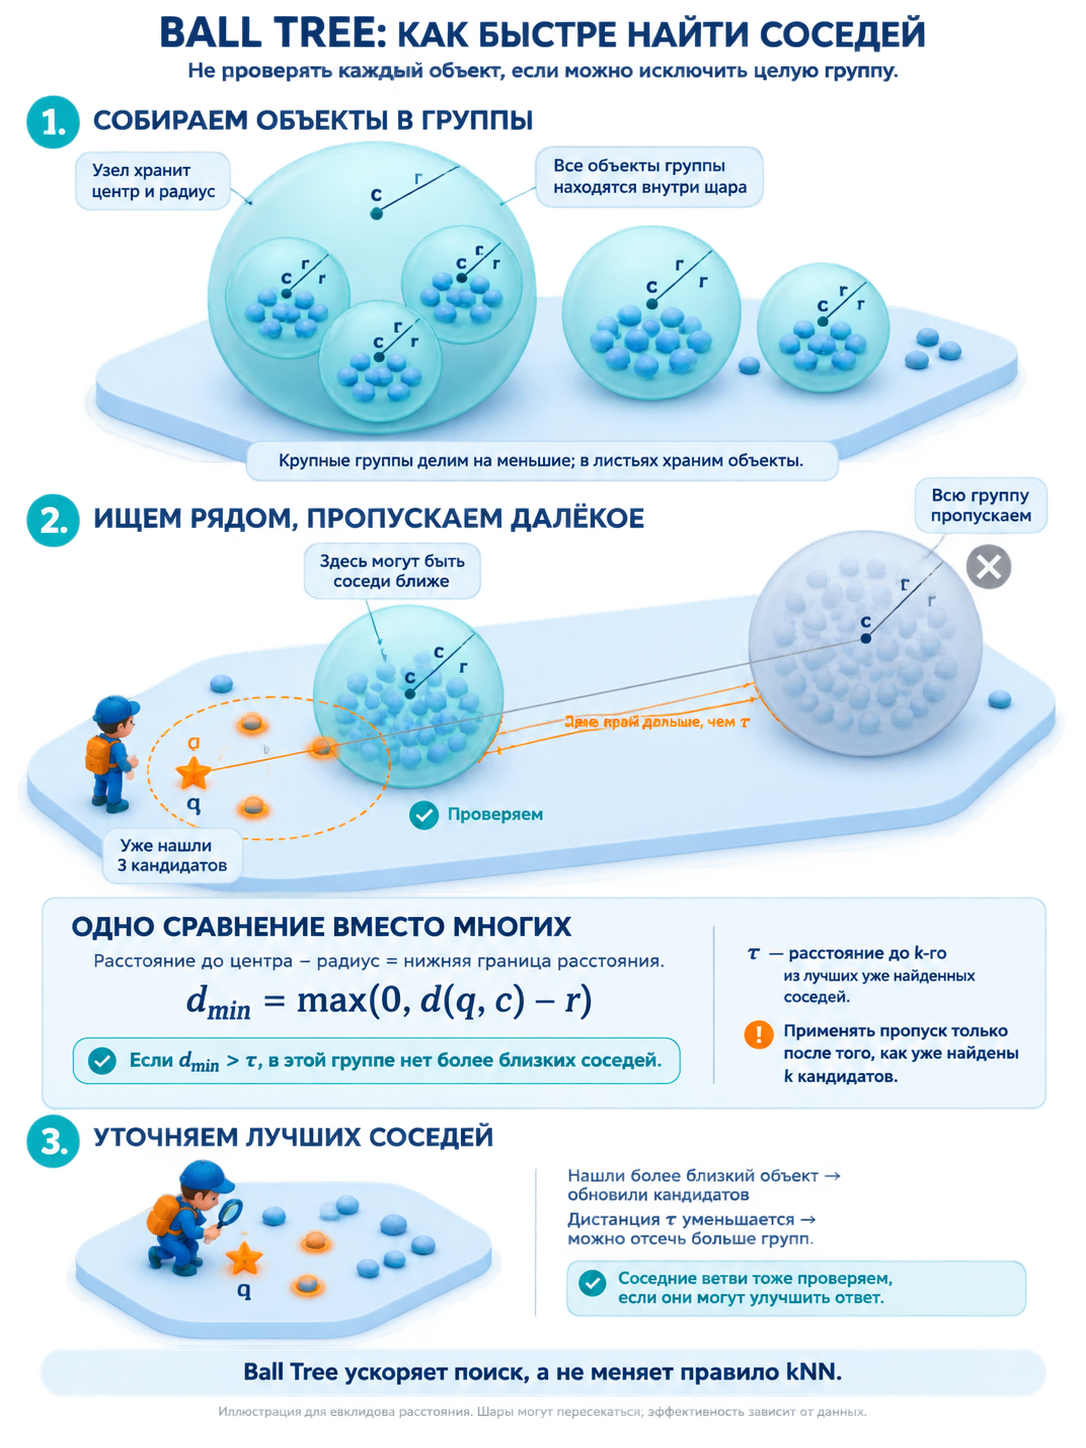

#### Выбираем k и веса на валидации

In [ ]:
knn_rows = []
knn_models = {}

for neighbor_count in [1, 3, 5, 11, 21, 51, 101]:
    for weighting in ['uniform', 'distance']:
        neighbor_model = KNeighborsClassifier(n_neighbors=neighbor_count, weights=weighting)
        neighbor_model.fit(cancer_train_scaled, cancer_train_target)
        knn_rows.append({
            'k': neighbor_count,
            'weights': weighting,
            'train_macro_f1': f1_score(cancer_train_target, neighbor_model.predict(cancer_train_scaled), average='macro'),
            'validation_macro_f1': f1_score(cancer_validation_target, neighbor_model.predict(cancer_validation_scaled), average='macro')
        })
        knn_models[(neighbor_count, weighting)] = neighbor_model

knn_results = pd.DataFrame(knn_rows)
knn_best_row = knn_results.sort_values(['validation_macro_f1', 'k', 'weights'], ascending=[False, False, False]).iloc[0]
selected_knn = knn_models[(int(knn_best_row['k']), knn_best_row['weights'])]
knn_results

,k,weights,train_macro_f1,validation_macro_f1
0,1,uniform,1.000000,0.944928
1,1,distance,1.000000,0.944928
2,3,uniform,0.977861,0.962302
3,3,distance,1.000000,0.962302
4,5,uniform,0.971535,0.971583
5,5,distance,1.000000,0.971583
6,11,uniform,0.958742,0.971583
7,11,distance,1.000000,0.971583
8,21,uniform,0.942138,0.961911
9,21,distance,1.000000,0.971583


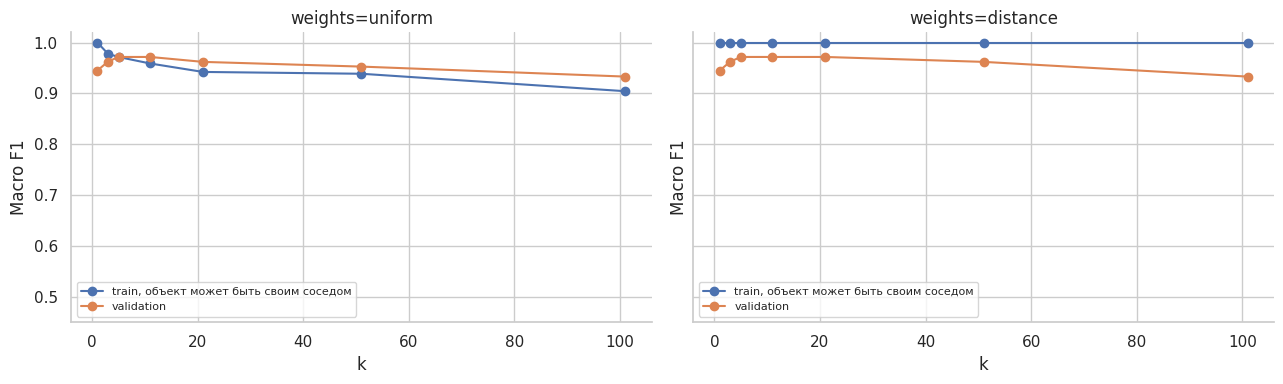

In [ ]:
figure_axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for ax, weighting in zip(axes, ['uniform', 'distance']):
    weight_subset = knn_results.loc[knn_results['weights'] == weighting]
    ax.plot(weight_subset['k'], weight_subset['train_macro_f1'], marker='o', label='train, объект может быть своим соседом')
    ax.plot(weight_subset['k'], weight_subset['validation_macro_f1'], marker='o', label='validation')
    ax.set(xlabel='k', ylabel='Macro F1', title=f'weights={weighting}', ylim=(0.45, 1.02))
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

#### Как k меняет границу

In [ ]:
moons_knn_models = {}
for neighbor_count in [1, 15, 61]:
    moons_neighbor_model = KNeighborsClassifier(n_neighbors=neighbor_count, weights='uniform')
    moons_neighbor_model.fit(moons_train_features, moons_train_target)
    moons_knn_models[neighbor_count] = moons_neighbor_model

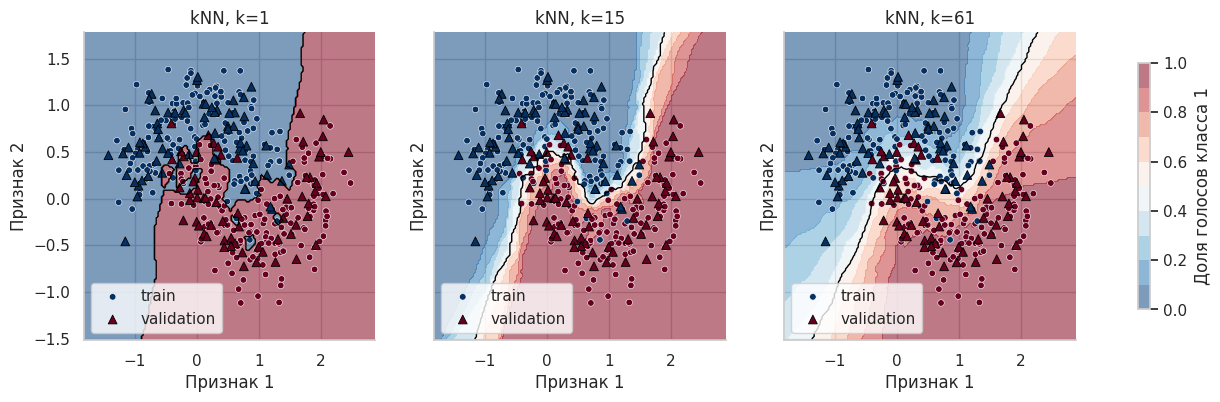

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for ax, model_item in zip(axes, moons_knn_models.items()):
    neighbor_count = model_item[0]
    neighbor_model = model_item[1]
    image = draw_binary_surface(
        neighbor_model, moons_train_features, moons_train_target, moons_validation_features, moons_validation_target, ax, f'kNN, k={neighbor_count}'
    )
figure.colorbar(image, ax=axes.tolist(), label='Доля голосов класса 1', shrink=0.8)
plt.show()

#### Влияние шума и дубликатов

StandardScaler не знает, какие признаки полезны. В стандартном евклидовом расстоянии каждый стандартизированный шумовой столбец тоже вносит вклад. Для эксперимента добавим 0, 5, 25 и 100 независимых шумовых признаков к тем же make_moons.

In [ ]:
noise_rows = []
for noise_seed in range(5):
    noise_generator = np.random.default_rng(100 + noise_seed)
    all_noise_features = noise_generator.normal(size=(len(moons_target), 100))
    for noise_count in [0, 5, 25, 100]:
        augmented_features = np.column_stack([moons_features, all_noise_features[:, :noise_count]])
        noise_scaler = StandardScaler()
        augmented_train = noise_scaler.fit_transform(augmented_features[moons_train_indices])
        augmented_validation = noise_scaler.transform(augmented_features[moons_validation_indices])
        noise_model = KNeighborsClassifier(n_neighbors=15)
        noise_model.fit(augmented_train, moons_train_target)
        noise_rows.append({
            'noise_seed': noise_seed,
            'noise_features': noise_count,
            'validation_macro_f1': f1_score(moons_validation_target, noise_model.predict(augmented_validation), average='macro')
        })

noise_results = pd.DataFrame(noise_rows)
noise_summary = noise_results.groupby('noise_features')['validation_macro_f1'].agg(['mean', 'min', 'max'])
noise_summary

,mean,min,max
noise_features,,,
0,0.880584,0.880584,0.880584
5,0.799071,0.776369,0.809091
25,0.754270,0.746032,0.760396
100,0.652860,0.622971,0.675926


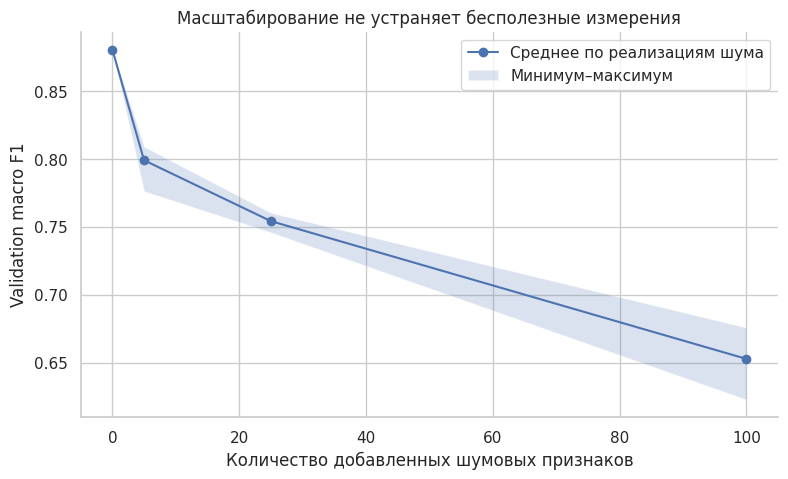

In [ ]:
figure = plt.figure(figsize=(9, 5))
plt.plot(noise_summary.index, noise_summary['mean'], marker='o', label='Среднее по реализациям шума')
plt.fill_between(noise_summary.index, noise_summary['min'], noise_summary['max'], alpha=0.2, label='Минимум–максимум')
plt.xlabel('Количество добавленных шумовых признаков')
plt.ylabel('Validation macro F1')
plt.title('Масштабирование не устраняет бесполезные измерения')
plt.legend()
plt.show()

Дублирование признака ещё более прозрачный пример: каждая копия добавляет тот же квадрат разности.
Это эквивалентно дополнительному весу признака в расстоянии, хотя новой информации не появилось.

In [ ]:
unit_multiplier = np.array([100.0, 1.0])
neighbor_example_features = np.array([[0.0, 0.0], [1.0, 0.2], [1.2, 0.8], [2.0, 1.0], [2.3, 0.3], [3.0, 1.4]])
neighbor_example_class = np.array([0, 0, 1, 1, 1, 0])
neighbor_query = np.array([[1.1, 0.4]])
neighbor_features_centimeters = neighbor_example_features * unit_multiplier
original_scaler = StandardScaler()
neighbor_original_standardized = original_scaler.fit_transform(neighbor_example_features)
original_query_standardized = original_scaler.transform(neighbor_query)
standardized_distances = np.linalg.norm(neighbor_original_standardized - original_query_standardized[0], axis=1)

In [ ]:
duplicated_coordinate_features = np.column_stack([neighbor_original_standardized, np.repeat(neighbor_original_standardized[:, [0]], 20, axis=1)])
duplicated_coordinate_query = np.column_stack([original_query_standardized, np.repeat(original_query_standardized[:, [0]], 20, axis=1)])
duplicated_coordinate_distances = np.linalg.norm(duplicated_coordinate_features - duplicated_coordinate_query[0], axis=1)

coordinate_duplication_table = pd.DataFrame({
    'object': np.arange(len(neighbor_example_class)),
    'distance_before': standardized_distances,
    'distance_after_20_copies': duplicated_coordinate_distances
})
coordinate_duplication_table

,object,distance_before,distance_after_20_copies
0,0,1.392526,5.240712
1,1,0.419828,0.622265
2,2,0.820597,0.940392
3,3,1.531584,4.408328
4,4,1.249130,5.651397
5,5,2.819661,9.170952


#### OHE и расстояние

Для столбца OHE с долей единиц p дисперсия равна $p(1-p)$. StandardScaler делит разность значений на $\sqrt{p(1-p)}$. Поэтому несовпадение в редкой категории даёт большой вклад в расстояние.


Проведем эксперимент - на маленьких данных изолируем эффект: 18 common, 1 rare_a и 1 rare_b. Сравним две подготовки:
1. Масштабируем только числовой признак, полный OHE оставляем 0/1.
2. Масштабируем все столбцы, включая OHE.

При полном невзвешенном OHE двух разных категорий одного исходного признака квадрат расстояния равен 2: отличаются две координаты. При `drop='first'` геометрия уже несимметрична: расстояние до базовой категории и между двумя небазовыми различается.

In [ ]:
ohe_categories = ['common'] * 18 + ['rare_a', 'rare_b']
ohe_data = pd.DataFrame({'numeric': np.linspace(-2, 2, 20), 'category': ohe_categories})
ohe_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_encoded = ohe_encoder.fit_transform(ohe_data[['category']])
ohe_columns = ohe_encoder.get_feature_names_out(['category'])
ohe_numeric_scaler = StandardScaler()
ohe_numeric_scaled = ohe_numeric_scaler.fit_transform(ohe_data[['numeric']])
ohe_mixed_features = np.column_stack([ohe_numeric_scaled, ohe_encoded])
ohe_all_scaler = StandardScaler()
ohe_all_scaled = ohe_all_scaler.fit_transform(ohe_mixed_features)
ohe_frequencies = ohe_encoded.mean(axis=0)

ohe_scale_audit = pd.DataFrame({
    'column': ohe_columns,
    'frequency': ohe_frequencies,
    'standard_deviation': np.sqrt(ohe_frequencies * (1 - ohe_frequencies)),
    'squared_cost_of_0_1_difference': 1 / (ohe_frequencies * (1 - ohe_frequencies))
})
ohe_scale_audit

,column,frequency,standard_deviation,squared_cost_of_0_1_difference
0,category_common,0.90,0.300000,11.111111
1,category_rare_a,0.05,0.217945,21.052632
2,category_rare_b,0.05,0.217945,21.052632


In [ ]:
category_prototypes = pd.DataFrame({'numeric': [0.0, 0.0, 0.0], 'category': ['common', 'rare_a', 'rare_b']})
prototype_features = np.column_stack([ohe_numeric_scaler.transform(category_prototypes[['numeric']]), ohe_encoder.transform(category_prototypes[['category']])])
prototype_scaled = ohe_all_scaler.transform(prototype_features)
prototype_distance_plain = np.linalg.norm(prototype_features[:, None, :] - prototype_features[None, :, :], axis=2)
prototype_distance_scaled = np.linalg.norm(prototype_scaled[:, None, :] - prototype_scaled[None, :, :], axis=2)
ohe_drop_encoder = OneHotEncoder(sparse_output=False, drop='first')
ohe_drop_encoder.fit(ohe_data[['category']])
prototype_drop = ohe_drop_encoder.transform(category_prototypes[['category']])
prototype_distance_drop = np.linalg.norm(prototype_drop[:, None, :] - prototype_drop[None, :, :], axis=2)

In [ ]:
c a b
1 0 0
1 0 0
0 1 0
0 0 1
1 0 0

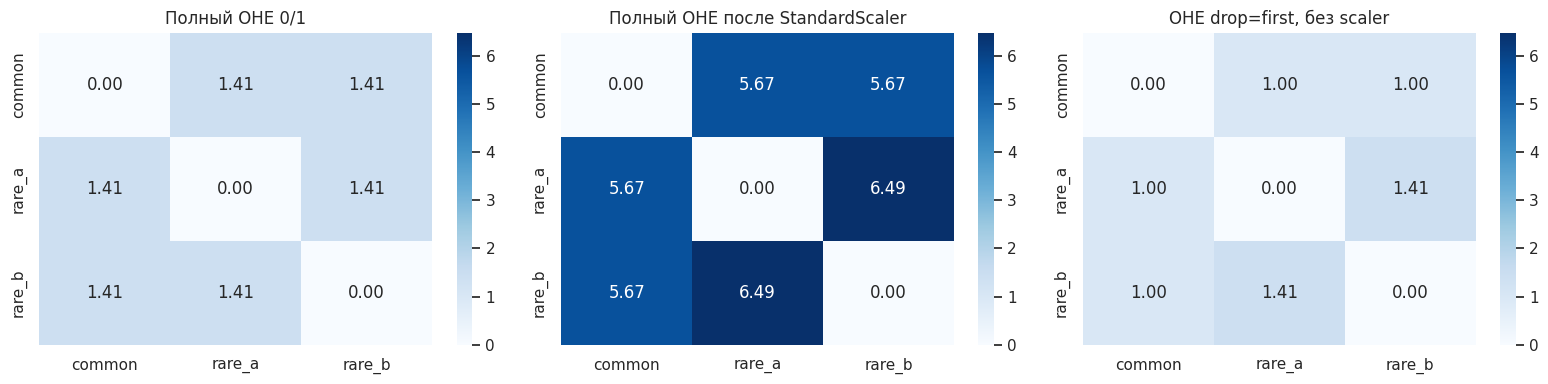

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4))
figure = figure_axes[0]
axes = figure_axes[1]
for ax, distances, title in zip(axes, [prototype_distance_plain, prototype_distance_scaled, prototype_distance_drop], ['Полный OHE 0/1', 'Полный OHE после StandardScaler', 'OHE drop=first, без scaler']):
    sns.heatmap(distances, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=prototype_distance_scaled.max(), xticklabels=category_prototypes['category'], yticklabels=category_prototypes['category'], ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Числовое значение прототипов одинаковое, поэтому различия на графике создаёт только кодирование категорий!

Вторая схема явно усиливает редкие несовпадения, третья делает расстояния несимметричными по отношению к выбору базовой категории.

В OHE `handle_unknown='ignore'` кодирует незнакомую категорию нулями. При полном OHE она имеет расстояние 1 до известных базисных векторов, тогда как две разные известные категории находятся на расстоянии $\sqrt(2)$. С drop='first' неизвестная категория ещё и неотличима в OHE-блоке от базовой.

#### kNN-регрессия - просто локальное усреднение

Сравним k=1, 9, 35 и uniform/distance.

In [ ]:
regression_generator = np.random.default_rng(random_state)
regression_features = regression_generator.uniform(0, 1, size=(300, 1))
regression_signal = 4 * (regression_features[:, 0] - 0.5) ** 2
regression_target = regression_signal + regression_generator.normal(0, 0.1, size=300)
regression_development_split = train_test_split(np.arange(len(regression_target)), test_size=0.2, random_state=random_state)
regression_development_indices = regression_development_split[0]
regression_test_indices = regression_development_split[1]
regression_train_split = train_test_split(regression_development_indices, test_size=0.25, random_state=random_state)
regression_train_indices = regression_train_split[0]
regression_validation_indices = regression_train_split[1]
regression_train_features = regression_features[regression_train_indices]
regression_validation_features = regression_features[regression_validation_indices]
regression_train_target = regression_target[regression_train_indices]
regression_validation_target = regression_target[regression_validation_indices]
regression_grid = np.linspace(0, 1, 500).reshape(-1, 1)
regression_dummy = DummyRegressor(strategy='mean')
regression_dummy.fit(regression_train_features, regression_train_target)

In [ ]:
knn_regression_models = {}
knn_regression_rows = []
for neighbor_count in [1, 9, 35]:
    for weighting in ['uniform', 'distance']:
        neighbor_regressor = KNeighborsRegressor(n_neighbors=neighbor_count, weights=weighting)
        neighbor_regressor.fit(regression_train_features, regression_train_target)
        knn_regression_models[(neighbor_count, weighting)] = neighbor_regressor
        knn_regression_rows.append({
            'k': neighbor_count,
            'weights': weighting,
            'train_rmse': regression_metrics(neighbor_regressor, regression_train_features, regression_train_target)['rmse'],
            'validation_rmse': regression_metrics(neighbor_regressor, regression_validation_features, regression_validation_target)['rmse']
        })
knn_regression_results = pd.DataFrame(knn_regression_rows)
knn_regression_best = knn_regression_results.sort_values(['validation_rmse', 'k'], ascending=[True, False]).iloc[0]
selected_knn_regressor = knn_regression_models[(int(knn_regression_best['k']), knn_regression_best['weights'])]
knn_regression_results

,k,weights,train_rmse,validation_rmse
0,1,uniform,0.000000,0.148686
1,1,distance,0.000000,0.148686
2,9,uniform,0.089404,0.105326
3,9,distance,0.000000,0.116372
4,35,uniform,0.117521,0.138522
5,35,distance,0.000000,0.120545


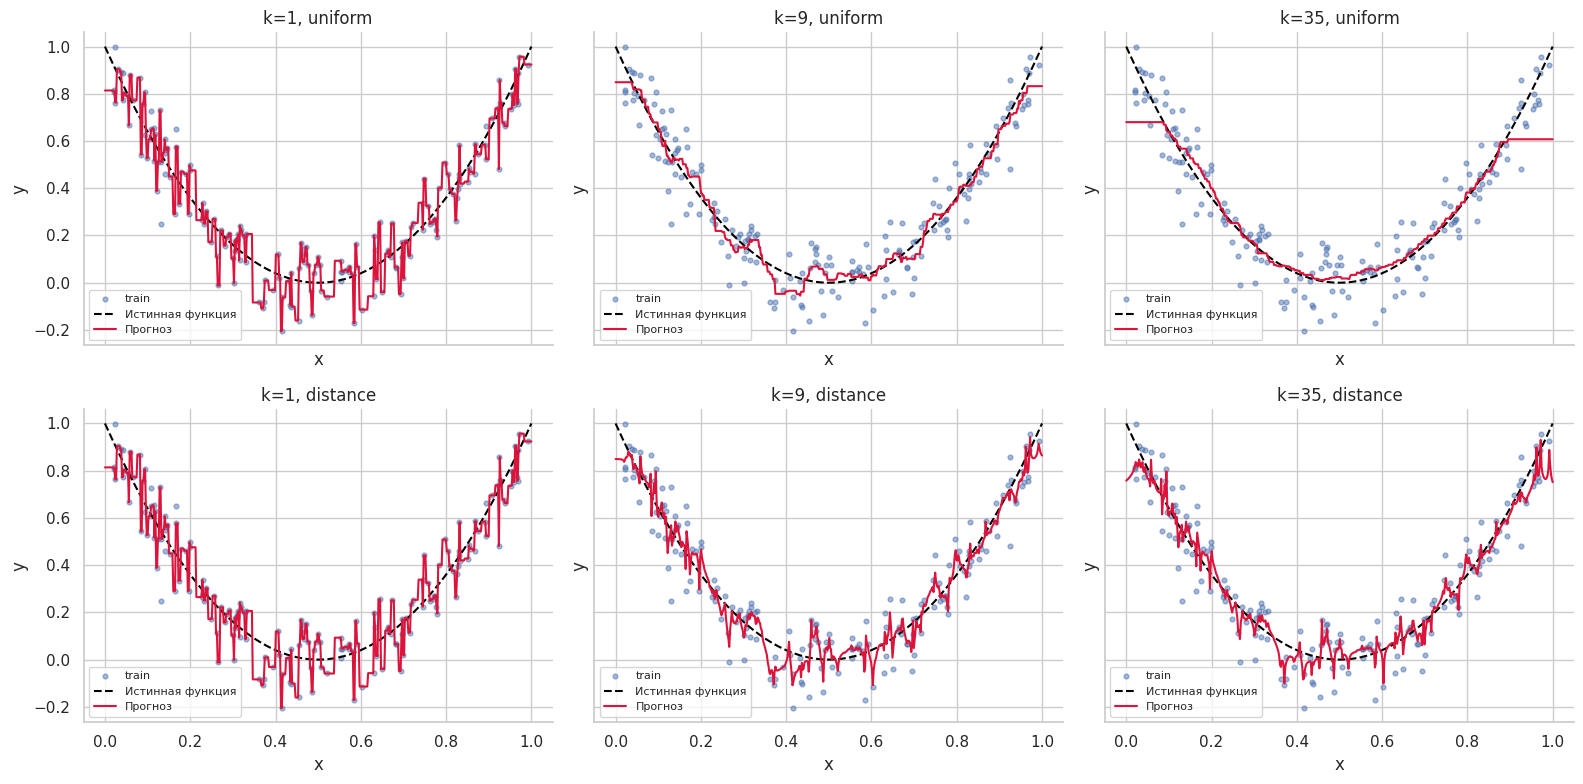

In [ ]:
figure_axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for row_position, weighting in enumerate(['uniform', 'distance']):
    for column_position, neighbor_count in enumerate([1, 9, 35]):
        ax = axes[row_position, column_position]
        neighbor_regressor = knn_regression_models[(neighbor_count, weighting)]
        ax.scatter(regression_train_features[:, 0], regression_train_target, s=12, alpha=0.5, label='train')
        ax.plot(regression_grid[:, 0], 4 * (regression_grid[:, 0] - 0.5) ** 2, color='black', linestyle='--', label='Истинная функция')
        ax.plot(regression_grid[:, 0], neighbor_regressor.predict(regression_grid), color='crimson', label='Прогноз')
        ax.set(xlabel='x', ylabel='y', title=f'k={neighbor_count}, {weighting}')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

В uniform-режиме прогноз кусочно-постоянен при фиксированном наборе соседей, в distance-режиме меняется с расстояниями. При точном попадании в train-объект distance может интерполировать его зашумлённый ответ даже при большом k. Поэтому большой k сам по себе не гарантирует отсутствие запоминания в distance-режиме.

Для обычного kNN с неотрицательными весами регрессионный прогноз лежит между ответами выбранных соседей. Это ограничивает экстраполяцию

### Дерево решений

[Давайте поиграем](https://ru.akinator.com/game)

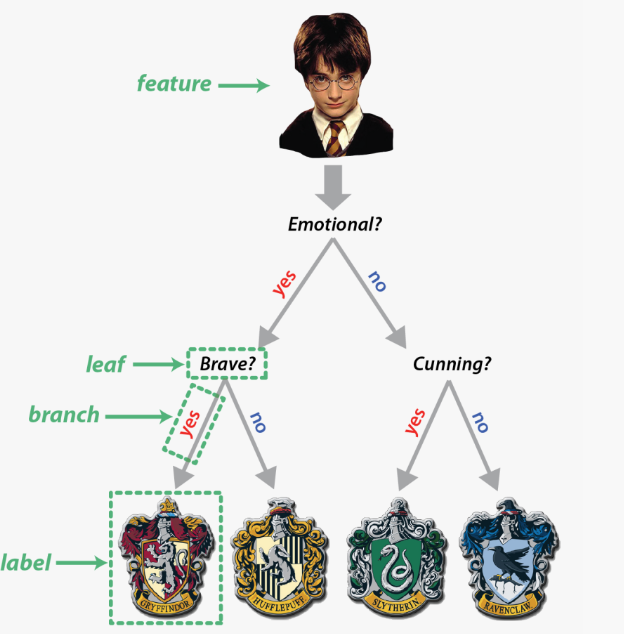

Дерево задаёт последовательность условий вида x_j <= t. В узле выбирается признак и порог, затем процедура повторяется в дочерних узлах. Алгоритм жадный: оптимизирует текущее разбиение, не перебирая все будущие деревья, и глобально оптимальное дерево не гарантирует.

In [ ]:
iris_tree_feature_names = iris.feature_names[2:]
iris_tree_train_features = iris.data.iloc[iris_train_indices, 2:]
iris_tree_validation_features = iris.data.iloc[iris_validation_indices, 2:]
iris_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=random_state)
iris_tree.fit(iris_tree_train_features, iris_train_target)

iris_tree_summary = pd.Series({
    'depth': iris_tree.get_depth(),
    'leaves': iris_tree.get_n_leaves(),
    'train_accuracy': accuracy_score(iris_train_target, iris_tree.predict(iris_tree_train_features)),
    'validation_accuracy': accuracy_score(iris_validation_target, iris_tree.predict(iris_tree_validation_features))
})
iris_tree_summary

,0
depth,3.000000
leaves,5.000000
train_accuracy,0.971429
validation_accuracy,0.888889


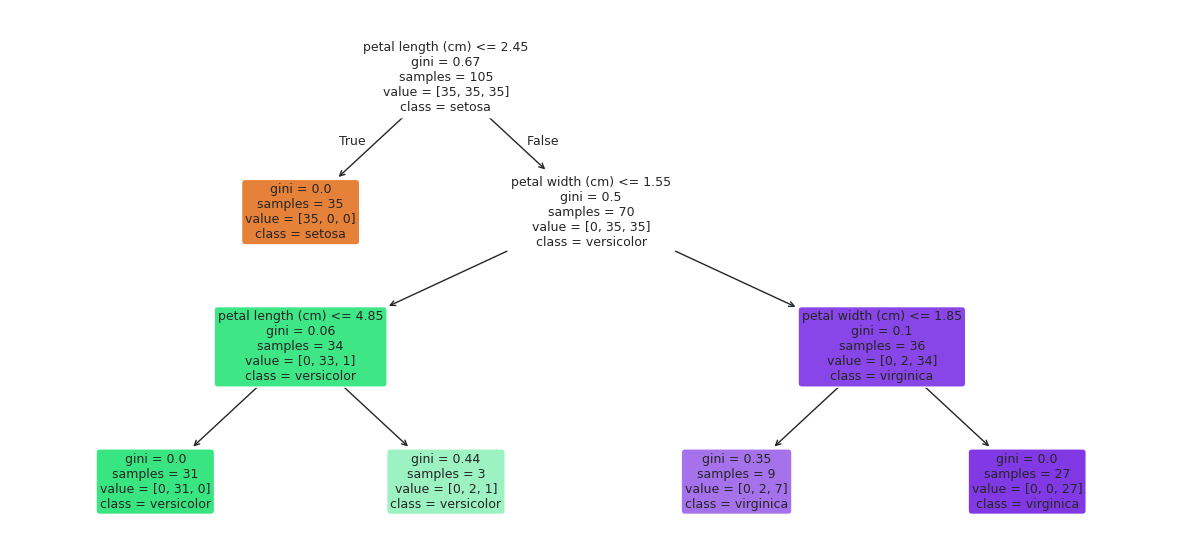

In [ ]:
figure = plt.figure(figsize=(15, 7))
plot_tree(iris_tree, feature_names=iris_tree_feature_names, class_names=iris.target_names.tolist(), filled=True, rounded=True, precision=2, fontsize=9)
plt.show()

#### Та же модель в SuperTree

In [ ]:
!pip install -q supertree

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 67.3 MB/s eta 0:00:00


In [ ]:
from supertree import SuperTree

iris_super_tree = SuperTree(iris_tree, iris_tree_train_features.to_numpy(), iris_train_target.to_numpy(), list(iris_tree_feature_names), iris.target_names.tolist())
iris_super_tree.show_tree()

#### Критерии разбиения

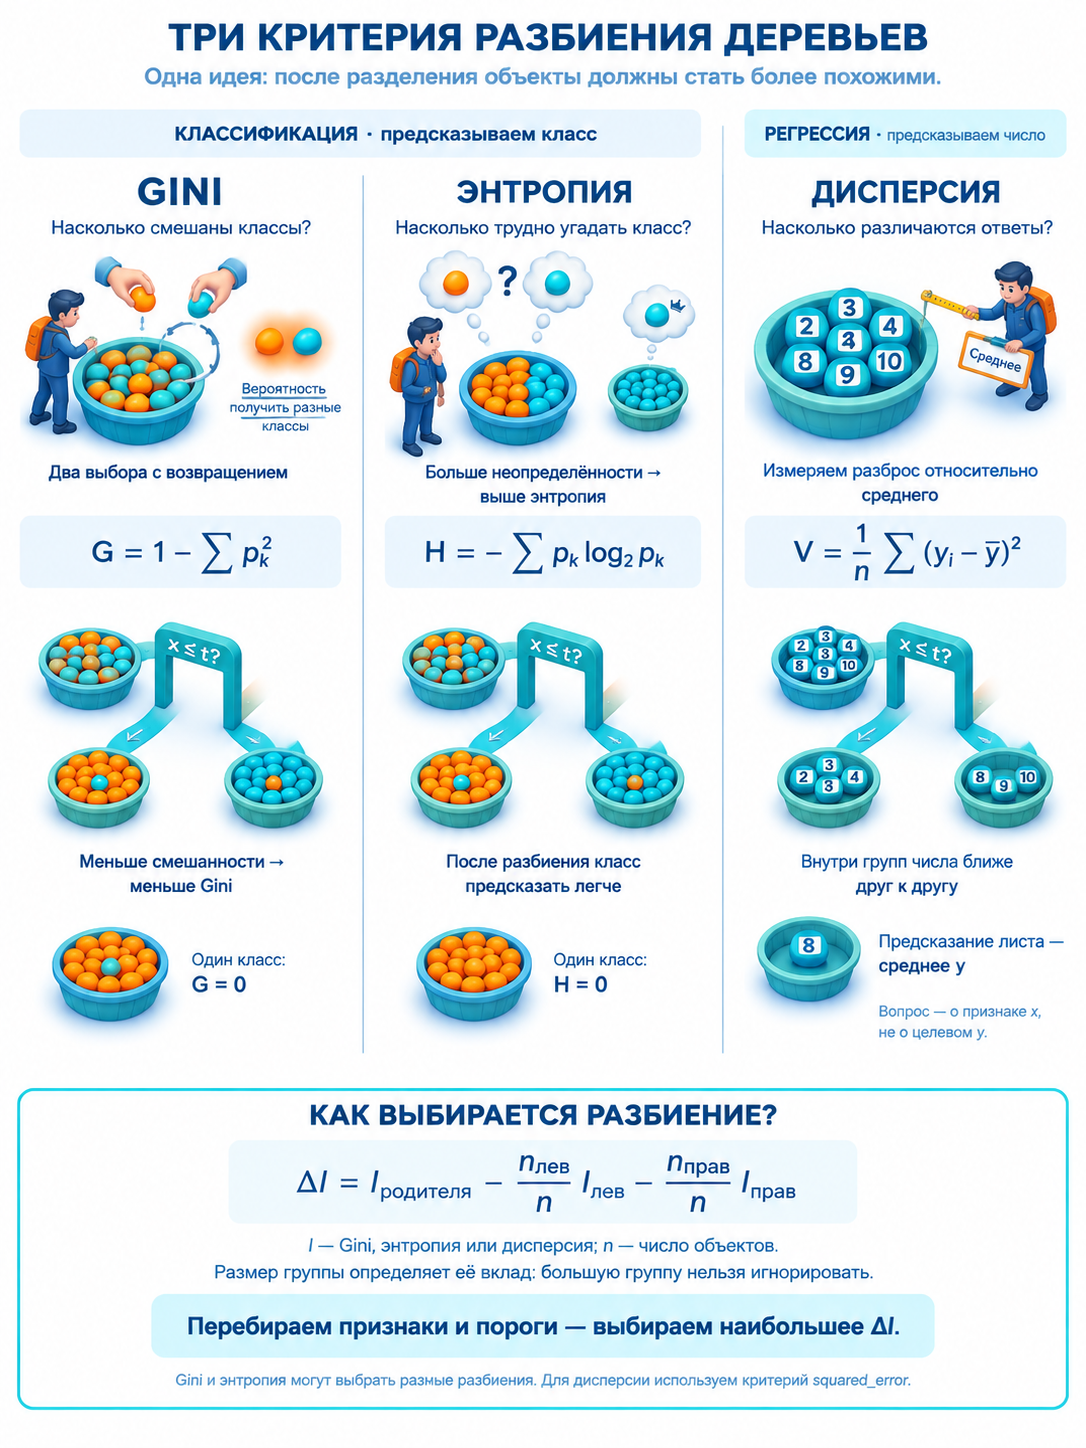

#### Ограничения дерева

Управляем сложностью до и во время роста:
- max_depth ограничивает длину пути;
- min_samples_leaf задаёт минимальное число строк в каждом листе;
- min_samples_split разрешает разбиение родителя только при достаточном числе объектов в нём, но не требует больших детей;
- max_leaf_nodes ограничивает число листьев.

In [ ]:
moons_tree_configurations = {'Без ограничений': {}, 'max_depth=3': {'max_depth': 3}, 'min_samples_leaf=15': {'min_samples_leaf': 15}}
moons_tree_models = {}
moons_tree_rows = []
for model_name, parameters in moons_tree_configurations.items():
    moons_tree = DecisionTreeClassifier(random_state=random_state, **parameters)
    moons_tree.fit(moons_train_features, moons_train_target)
    moons_tree_models[model_name] = moons_tree
    moons_tree_rows.append({
        'model': model_name,
        'depth': moons_tree.get_depth(),
        'leaves': moons_tree.get_n_leaves(),
        'train_macro_f1': f1_score(moons_train_target, moons_tree.predict(moons_train_features), average='macro'),
        'validation_macro_f1': f1_score(moons_validation_target, moons_tree.predict(moons_validation_features), average='macro')
    })
moons_tree_results = pd.DataFrame(moons_tree_rows)
moons_tree_results

,model,depth,leaves,train_macro_f1,validation_macro_f1
0,Без ограничений,10,26,1.000000,0.880038
1,max_depth=3,3,6,0.931894,0.864387
2,min_samples_leaf=15,5,11,0.914941,0.840909


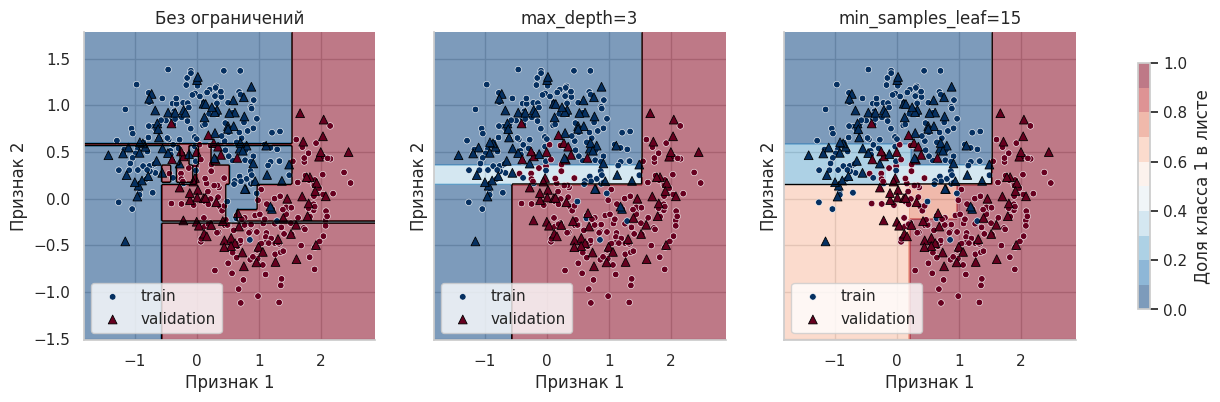

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]
for ax, model_item in zip(axes, moons_tree_models.items()):
    image = draw_binary_surface(model_item[1], moons_train_features, moons_train_target, moons_validation_features, moons_validation_target, ax, model_item[0])
figure.colorbar(image, ax=axes.tolist(), label='Доля класса 1 в листе', shrink=0.8)
plt.show()

Ограничение сложности сокращает мелкие области, но не гарантирует улучшения на каждом конкретном split

#### ccp_alpha - сначала вырастить, затем обрезать

Предварительные ограничения запрещают часть разбиений. Cost-complexity pruning рассматривает поддеревья уже выращенного дерева и балансирует ошибку с числом листьев:

R_alpha(T) = R(T) + alpha × число листьев.

В sklearn R(T) связано со взвешенной суммой нечистот листьев. Больший ccp_alpha сильнее штрафует сложность.

Получаем кандидаты из cost_complexity_pruning_path только на train. Затем обучаем поддеревья и выбираем alpha на validation.

In [ ]:
pruning_base = DecisionTreeClassifier(random_state=random_state)
pruning_path = pruning_base.cost_complexity_pruning_path(cancer_train_features, cancer_train_target)
pruning_alphas = np.unique(pruning_path.ccp_alphas)
pruning_rows = []
pruning_models = {}
for alpha in pruning_alphas:
    pruned_tree = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=random_state)
    pruned_tree.fit(cancer_train_features, cancer_train_target)
    pruning_rows.append({
        'alpha': alpha,
        'leaves': pruned_tree.get_n_leaves(),
        'depth': pruned_tree.get_depth(),
        'train_macro_f1': f1_score(cancer_train_target, pruned_tree.predict(cancer_train_features), average='macro'),
        'validation_macro_f1': f1_score(cancer_validation_target, pruned_tree.predict(cancer_validation_features), average='macro')
    })
    pruning_models[float(alpha)] = pruned_tree

pruning_results = pd.DataFrame(pruning_rows)
pruning_best_row = pruning_results.sort_values(['validation_macro_f1', 'leaves', 'alpha'], ascending=[False, True, False]).iloc[0]
selected_pruning_alpha = float(pruning_best_row['alpha'])
selected_pruned_tree = pruning_models[selected_pruning_alpha]
pruning_results

,alpha,leaves,depth,train_macro_f1,validation_macro_f1
0,0.000000,17,6,1.000000,0.898634
1,0.002903,13,5,0.993706,0.916361
2,0.002906,11,4,0.990575,0.907468
3,0.003910,9,4,0.984291,0.907468
4,0.005279,8,3,0.981118,0.915590
5,0.007403,7,3,0.978078,0.915590
6,0.007472,6,3,0.974825,0.915590
7,0.008379,5,3,0.968426,0.915590
8,0.018264,4,3,0.959414,0.934947
9,0.024885,3,2,0.935373,0.900119


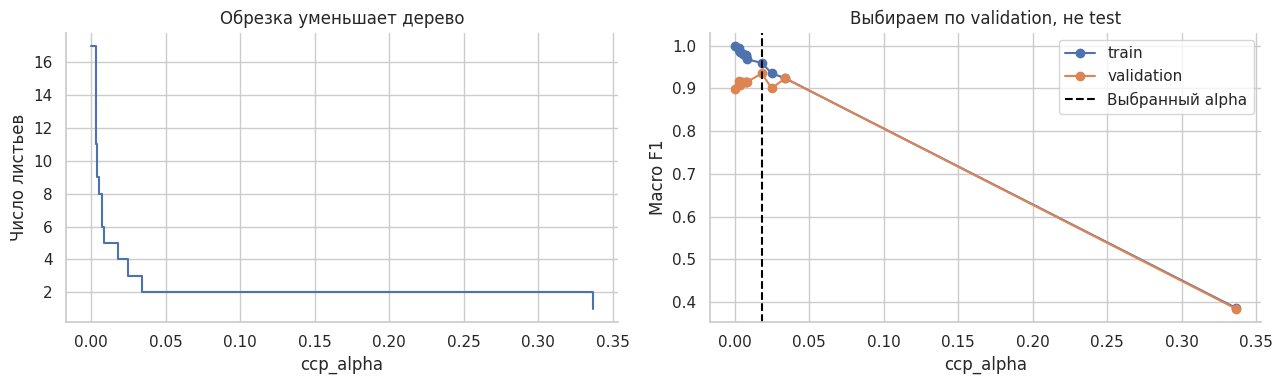

In [ ]:
figure_axes = plt.subplots(1, 2, figsize=(13, 4))
figure = figure_axes[0]
axes = figure_axes[1]
axes[0].step(pruning_results['alpha'], pruning_results['leaves'], where='post')
axes[0].set(xlabel='ccp_alpha', ylabel='Число листьев', title='Обрезка уменьшает дерево')
axes[1].plot(pruning_results['alpha'], pruning_results['train_macro_f1'], marker='o', label='train')
axes[1].plot(pruning_results['alpha'], pruning_results['validation_macro_f1'], marker='o', label='validation')
axes[1].axvline(selected_pruning_alpha, color='black', linestyle='--', label='Выбранный alpha')
axes[1].set(xlabel='ccp_alpha', ylabel='Macro F1', title='Выбираем по validation, не test')
axes[1].legend()
plt.tight_layout()
plt.show()

Сравним pruning с небольшой сеткой max_depth/min_samples_leaf на тех же полных признаках Breast Cancer. Выбор внутри семейства деревьев делаем по validation macro F1, а при равенстве в пользу меньшего числа листьев.

NB: Частые попытки и ручные решения, принятые по одной validation тоже способны переобучить модель. Более устойчивые схемы оценки рассмотрим далее в курсе.

In [ ]:
prepruning_rows = []
prepruning_models = {}

for maximum_depth in [2, 3, 5, None]:
    for minimum_leaf in [1, 5, 15]:
        prepruned_tree = DecisionTreeClassifier(max_depth=maximum_depth, min_samples_leaf=minimum_leaf, random_state=random_state)
        prepruned_tree.fit(cancer_train_features, cancer_train_target)
        model_key = f'depth={maximum_depth}, leaf={minimum_leaf}'
        prepruning_models[model_key] = prepruned_tree
        prepruning_rows.append({
            'name': model_key,
            'leaves': prepruned_tree.get_n_leaves(),
            'validation_macro_f1': f1_score(cancer_validation_target, prepruned_tree.predict(cancer_validation_features), average='macro')
        })

prepruning_results = pd.DataFrame(prepruning_rows)
prepruning_best_row = prepruning_results.sort_values(['validation_macro_f1', 'leaves', 'name'], ascending=[False, True, True]).iloc[0]
prepruning_best_model = prepruning_models[prepruning_best_row['name']]
tree_selection_table = pd.DataFrame({
    'method': ['Предварительные ограничения', 'ccp_alpha'],
    'validation_macro_f1': [prepruning_best_row['validation_macro_f1'], pruning_best_row['validation_macro_f1']],
    'leaves': [prepruning_best_model.get_n_leaves(), selected_pruned_tree.get_n_leaves()]
})
tree_selection_best = tree_selection_table.sort_values(['validation_macro_f1', 'leaves'], ascending=[False, True]).iloc[0]['method']
selected_cancer_tree = prepruning_best_model if tree_selection_best == 'Предварительные ограничения' else selected_pruned_tree
tree_selection_table

,method,validation_macro_f1,leaves
0,Предварительные ограничения,0.925974,16
1,ccp_alpha,0.934947,4


#### Поворот пространства: дерево зависит от осей

In [ ]:
rotation_generator = np.random.default_rng(random_state)
rotation_features = rotation_generator.uniform(-1, 1, size=(400, 2))
rotation_target = (rotation_features[:, 0] > 0).astype(int)
rotation_angle = np.pi / 4
rotation_matrix = np.array([[np.cos(rotation_angle), -np.sin(rotation_angle)], [np.sin(rotation_angle), np.cos(rotation_angle)]])
rotated_features = rotation_features @ rotation_matrix
rotation_split = train_test_split(np.arange(400), test_size=0.3, stratify=rotation_target, random_state=random_state)
rotation_train_indices = rotation_split[0]
rotation_validation_indices = rotation_split[1]
rotation_trees = []
rotation_neighbors = []
rotation_rows = []

for representation_name, feature_values in [('Исходные оси', rotation_features), ('Поворот на 45 градусов', rotated_features)]:
    rotation_tree = DecisionTreeClassifier(min_samples_leaf=5, random_state=random_state)
    rotation_tree.fit(feature_values[rotation_train_indices], rotation_target[rotation_train_indices])
    rotation_neighbor = KNeighborsClassifier(n_neighbors=9)
    rotation_neighbor.fit(feature_values[rotation_train_indices], rotation_target[rotation_train_indices])
    rotation_trees.append(rotation_tree)
    rotation_neighbors.append(rotation_neighbor)
    rotation_rows.append({
        'representation': representation_name,
        'tree_leaves': rotation_tree.get_n_leaves(),
        'tree_validation_accuracy': accuracy_score(rotation_target[rotation_validation_indices], rotation_tree.predict(feature_values[rotation_validation_indices]))
    })

rotation_results = pd.DataFrame(rotation_rows)
rotation_results

,representation,tree_leaves,tree_validation_accuracy
0,Исходные оси,2,1.000000
1,Поворот на 45 градусов,11,0.958333


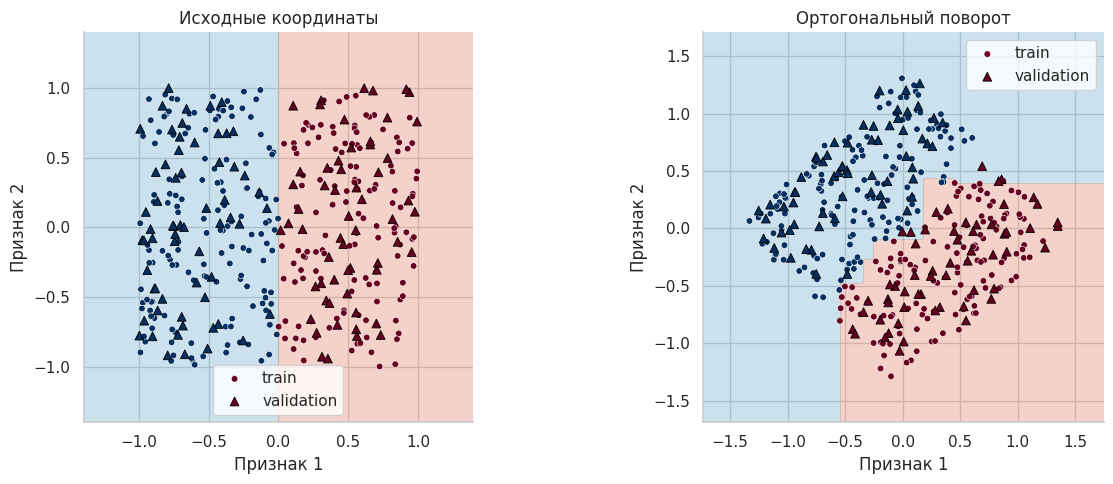

In [ ]:
figure_axes = plt.subplots(1, 2, figsize=(13, 5))
figure = figure_axes[0]
axes = figure_axes[1]

for ax, tree_model, feature_values, title in zip(axes, rotation_trees, [rotation_features, rotated_features], ['Исходные координаты', 'Ортогональный поворот']):
    draw_binary_surface(
        tree_model,
        feature_values[rotation_train_indices],
        rotation_target[rotation_train_indices],
        feature_values[rotation_validation_indices],
        rotation_target[rotation_validation_indices],
        ax,
        title,
        probability=False,
    )
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

#### Регрессия в листах - среднее или медиана

In [ ]:
tree_regression_configurations = {'depth=2': {'max_depth': 2}, 'depth=3': {'max_depth': 3}, 'Без ограничений': {}, 'leaf=10': {'min_samples_leaf': 10}}
tree_regression_models = {}
tree_regression_rows = []
for model_name, parameters in tree_regression_configurations.items():
    regression_tree = DecisionTreeRegressor(random_state=random_state, **parameters)
    regression_tree.fit(regression_train_features, regression_train_target)
    tree_regression_models[model_name] = regression_tree
    tree_regression_rows.append({
        'model': model_name,
        'leaves': regression_tree.get_n_leaves(),
        'depth': regression_tree.get_depth(),
        'train_rmse': regression_metrics(regression_tree, regression_train_features, regression_train_target)['rmse'],
        'validation_rmse': regression_metrics(regression_tree, regression_validation_features, regression_validation_target)['rmse']
    })

tree_regression_results = pd.DataFrame(tree_regression_rows)
best_regression_tree_name = tree_regression_results.sort_values(['validation_rmse', 'leaves'], ascending=[True, True]).iloc[0]['model']
selected_tree_regressor = tree_regression_models[best_regression_tree_name]
tree_regression_results

,model,leaves,depth,train_rmse,validation_rmse
0,depth=2,4,2,0.147955,0.185195
1,depth=3,8,3,0.113258,0.140337
2,Без ограничений,180,20,0.000000,0.148686
3,leaf=10,14,8,0.088033,0.132354


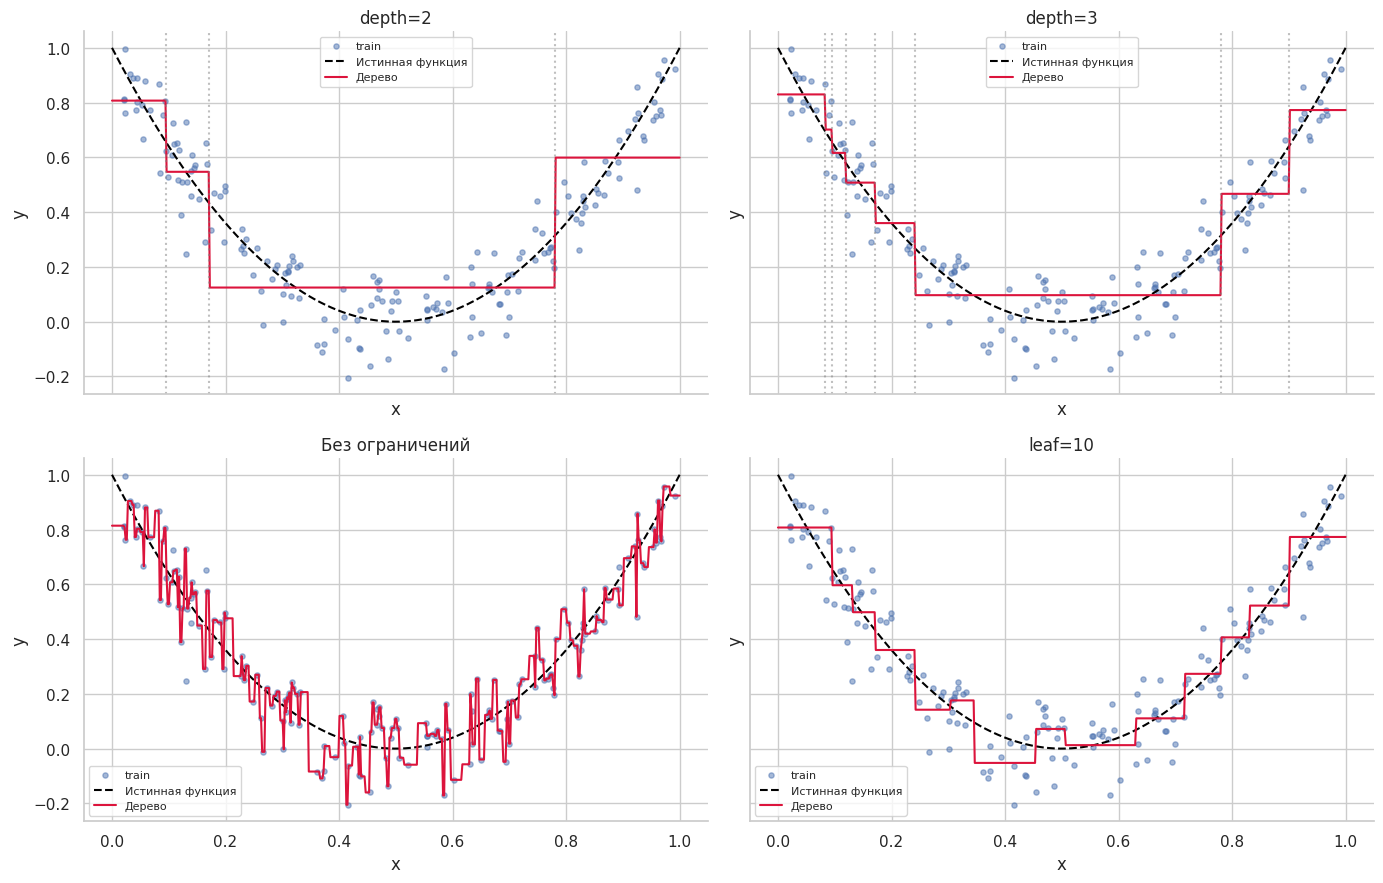

In [ ]:
figure_axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]
for ax, model_item in zip(axes.ravel(), tree_regression_models.items()):
    regression_tree = model_item[1]
    ax.scatter(regression_train_features[:, 0], regression_train_target, s=14, alpha=0.5, label='train')
    ax.plot(regression_grid[:, 0], 4 * (regression_grid[:, 0] - 0.5) ** 2, color='black', linestyle='--', label='Истинная функция')
    ax.plot(regression_grid[:, 0], regression_tree.predict(regression_grid), color='crimson', label='Дерево')
    if regression_tree.get_depth() <= 3:
        internal_mask = regression_tree.tree_.children_left != -1
        for threshold in regression_tree.tree_.threshold[internal_mask]:
            ax.axvline(threshold, color='gray', alpha=0.5, linestyle=':')
    ax.set(xlabel='x', ylabel='y', title=model_item[0])
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Сравним три модели

#### Классификация

In [ ]:
geometry_models = {'Логистическая регрессия': moons_logistic_models[1.0], 'kNN, k=15': moons_knn_models[15], 'Дерево, leaf=15': moons_tree_models['min_samples_leaf=15']}
geometry_rows = []

for model_name, model in geometry_models.items():
    geometry_result = classification_metrics(model, moons_validation_features, moons_validation_target)
    geometry_result['model'] = model_name
    geometry_rows.append(geometry_result)

geometry_results = pd.DataFrame(geometry_rows).set_index('model')
geometry_results

,accuracy,macro_f1,precision_1,recall_1,roc_auc,log_loss
model,,,,,,
Логистическая регрессия,0.785714,0.784615,0.833333,0.714286,0.892164,0.434391
"kNN, k=15",0.880952,0.880765,0.913793,0.841270,0.957420,0.756994
"Дерево, leaf=15",0.841270,0.840909,0.877193,0.793651,0.876921,2.260889


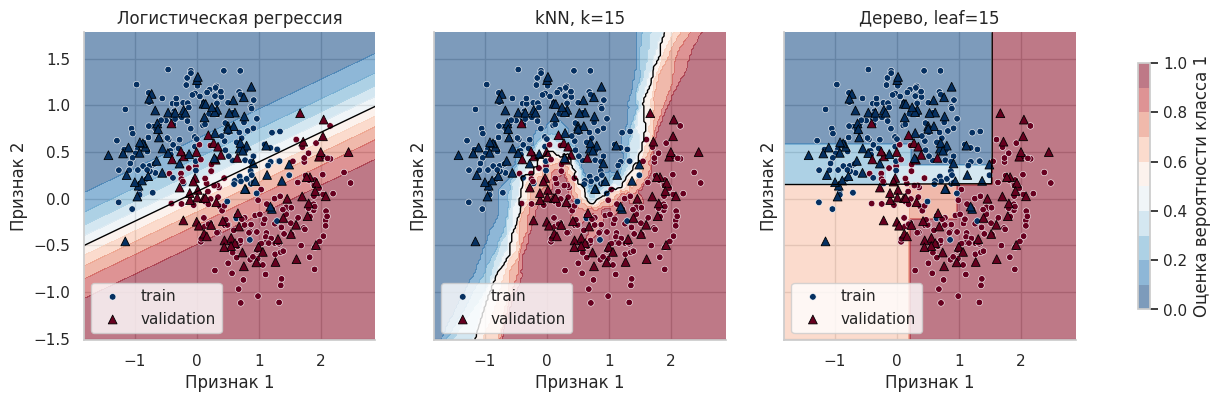

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for ax, model_item in zip(axes, geometry_models.items()):
    image = draw_binary_surface(model_item[1], moons_train_features, moons_train_target, moons_validation_features, moons_validation_target, ax, model_item[0])

figure.colorbar(image, ax=axes.tolist(), label='Оценка вероятности класса 1', shrink=0.8)
plt.show()

#### Регрессия с экстраполяцией

In [ ]:
extrapolation_generator = np.random.default_rng(7)
extrapolation_features = np.linspace(0, 1, 60).reshape(-1, 1)
extrapolation_target = 2 + 3 * extrapolation_features[:, 0] + extrapolation_generator.normal(0, 0.15, 60)
extrapolation_grid = np.linspace(-0.6, 1.6, 400).reshape(-1, 1)
extrapolation_models = {
    'Линейная регрессия': LinearRegression(),
    'kNN, uniform': KNeighborsRegressor(n_neighbors=7),
    'Дерево, leaf=5': DecisionTreeRegressor(min_samples_leaf=5, random_state=random_state)
}

for model in extrapolation_models.values():
    model.fit(extrapolation_features, extrapolation_target)

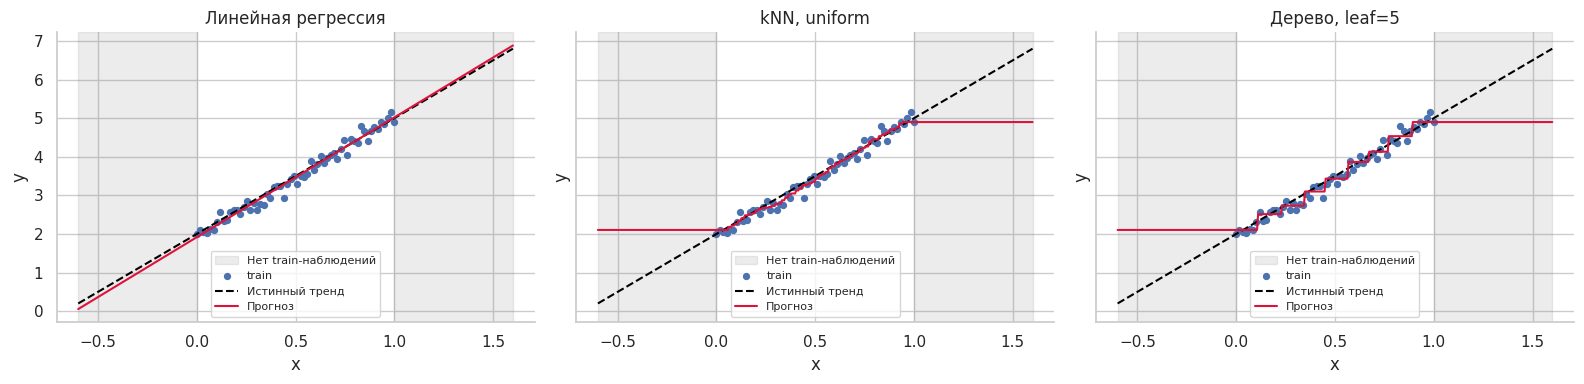

In [ ]:
figure_axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
figure = figure_axes[0]
axes = figure_axes[1]

for ax, model_item in zip(axes, extrapolation_models.items()):
    ax.axvspan(-0.6, 0, color='gray', alpha=0.15)
    ax.axvspan(1, 1.6, color='gray', alpha=0.15, label='Нет train-наблюдений')
    ax.scatter(extrapolation_features[:, 0], extrapolation_target, s=18, label='train')
    ax.plot(extrapolation_grid[:, 0], 2 + 3 * extrapolation_grid[:, 0], color='black', linestyle='--', label='Истинный тренд')
    ax.plot(extrapolation_grid[:, 0], model_item[1].predict(extrapolation_grid), color='crimson', label='Прогноз')
    ax.set(xlabel='x', ylabel='y', title=model_item[0])
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

#### Breast Cancer Test

In [ ]:
cancer_test_scaled = pd.DataFrame(cancer_scaler.transform(cancer_test_features), columns=cancer_features.columns, index=cancer_test_indices)
final_classifier_inputs = {
    'Dummy': (cancer_dummy, cancer_test_features),
    'LogisticRegression, predict': (selected_logistic, cancer_test_scaled),
    'kNN': (selected_knn, cancer_test_scaled),
    'DecisionTree': (selected_cancer_tree, cancer_test_features)
}

final_classification_rows = []
for model_name, model_input in final_classifier_inputs.items():
    result = classification_metrics(model_input[0], model_input[1], cancer_test_target)
    result['model'] = model_name
    final_classification_rows.append(result)

final_classification_results = pd.DataFrame(final_classification_rows).set_index('model')
final_classification_results

,accuracy,macro_f1,precision_1,recall_1,roc_auc,log_loss
model,,,,,,
Dummy,0.631579,0.387097,0.000000,0.000000,0.500000,0.658144
"LogisticRegression, predict",0.973684,0.971583,0.975610,0.952381,0.995370,0.079026
kNN,0.947368,0.942230,0.973684,0.880952,0.996362,0.115004
DecisionTree,0.929825,0.923822,0.925000,0.880952,0.938988,0.538239
